In [8]:
import pandas as pd
import numpy as np

df = pd.read_csv("survey_sample.csv")

display(df.head())

print("Columns:", df.columns.tolist())
print("Total rows:", len(df))


,student_id,advertising_exposure,perceived_credibility,purchase_intention,purchase_decision,social_media_usage,shopping_frequency,monthly_budget
0,1,5,4,5,1,5,4,4
1,2,2,3,2,0,3,2,2
2,3,4,5,4,1,4,3,3
3,4,1,2,1,0,2,1,1
4,5,3,4,3,0,4,2,3


Columns: ['student_id', 'advertising_exposure', 'perceived_credibility', 'purchase_intention', 'purchase_decision', 'social_media_usage', 'shopping_frequency', 'monthly_budget']
Total rows: 8


In [9]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

Missing values:
student_id               0
advertising_exposure     0
perceived_credibility    0
purchase_intention       0
purchase_decision        0
social_media_usage       0
shopping_frequency       0
monthly_budget           0
dtype: int64

Duplicate rows:
0

Data types:
student_id               int64
advertising_exposure     int64
perceived_credibility    int64
purchase_intention       int64
purchase_decision        int64
social_media_usage       int64
shopping_frequency       int64
monthly_budget           int64
dtype: object


In [10]:
columns = df.columns.drop("student_id")

Q1 = df[columns].quantile(0.25)
Q3 = df[columns].quantile(0.75)

IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = (
    (df[columns] < lower) |
    (df[columns] > upper)
)
print("Outliers per column:")
print(outliers.sum())

print("\nTotal outlier cells:")
print(outliers.sum().sum())

Outliers per column:
advertising_exposure     0
perceived_credibility    0
purchase_intention       0
purchase_decision        0
social_media_usage       0
shopping_frequency       0
monthly_budget           0
dtype: int64

Total outlier cells:
0


In [11]:
columns = df.columns.drop("student_id")

summary = pd.DataFrame({
    "Mean": df[columns].mean(),
    "SD": df[columns].std(),
    "Median": df[columns].median(),
    "p95": df[columns].quantile(0.95),
    "p99": df[columns].quantile(0.99)
})

print("Statistical Summary:")
display(summary.round(2))

Statistical Summary:


,Mean,SD,Median,p95,p99
advertising_exposure,3.25,1.49,3.5,5.00,5.00
perceived_credibility,3.50,1.20,3.5,5.00,5.00
purchase_intention,3.38,1.41,3.5,5.00,5.00
purchase_decision,0.50,0.53,0.5,1.00,1.00
social_media_usage,3.75,1.04,4.0,5.00,5.00
shopping_frequency,2.88,1.36,2.5,4.65,4.93
monthly_budget,3.00,1.31,3.0,4.65,4.93


In [12]:
import numpy as np

np.random.seed(42)

ci_lower = []
ci_upper = []

for col in columns:
    data = df[col].dropna().values
    bootstrap_means = []

    for i in range(1000):
        sample = np.random.choice(
            data,
            size=len(data),
            replace=True
        )
        bootstrap_means.append(np.mean(sample))

    ci_lower.append(np.percentile(bootstrap_means, 2.5))
    ci_upper.append(np.percentile(bootstrap_means, 97.5))

summary["CI Lower"] = ci_lower
summary["CI Upper"] = ci_upper

print("Statistical Summary with 95% CI:")
display(summary.round(2))

Statistical Summary with 95% CI:


,Mean,SD,Median,p95,p99,CI Lower,CI Upper
advertising_exposure,3.25,1.49,3.5,5.00,5.00,2.25,4.25
perceived_credibility,3.50,1.20,3.5,5.00,5.00,2.75,4.25
purchase_intention,3.38,1.41,3.5,5.00,5.00,2.38,4.25
purchase_decision,0.50,0.53,0.5,1.00,1.00,0.12,0.88
social_media_usage,3.75,1.04,4.0,5.00,5.00,3.00,4.38
shopping_frequency,2.88,1.36,2.5,4.65,4.93,2.00,3.75
monthly_budget,3.00,1.31,3.0,4.65,4.93,2.25,3.88


In [13]:
import os

os.makedirs("data/processed", exist_ok=True)

summary.to_csv(
    "data/processed/metrics_summary.csv",
    index_label="metric"
)

print("File saved successfully!")

File saved successfully!


In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(
    style="whitegrid",
    palette="colorblind",
    font_scale=1.2
)
print("Visualization libraries loaded!")

Visualization libraries loaded!


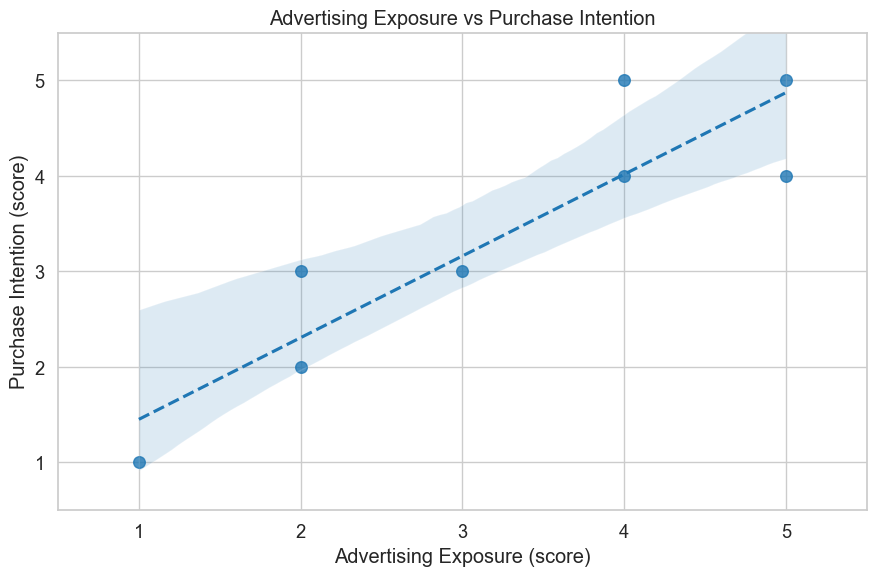

In [15]:
plt.figure(figsize=(9, 6))

sns.regplot(
    data=df,
    x="advertising_exposure",
    y="purchase_intention",
    ci=95,
    color="tab:blue",
    scatter_kws={"s": 70, "alpha": 0.8},
    line_kws={"linestyle": "--"}
)

plt.xlabel("Advertising Exposure (score)")
plt.ylabel("Purchase Intention (score)")
plt.title("Advertising Exposure vs Purchase Intention")

plt.xticks([1, 2, 3, 4, 5])
plt.yticks([1, 2, 3, 4, 5])

plt.xlim(0.5, 5.5)
plt.ylim(0.5, 5.5)

plt.tight_layout()
plt.show()

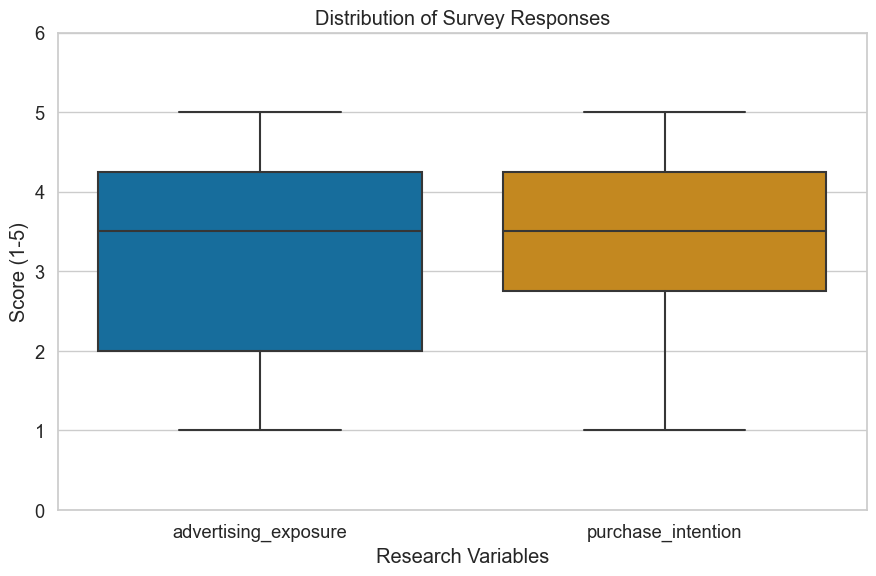

In [16]:
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df[
        ["advertising_exposure", "purchase_intention"]
    ],
    palette="colorblind"
)

plt.xlabel("Research Variables")
plt.ylabel("Score (1-5)")
plt.title("Distribution of Survey Responses")

plt.ylim(0, 6)
plt.tight_layout()
plt.show()

In [18]:
import os
os.makedirs("reports/figures", exist_ok=True)
print("Figures folder created!")

Figures folder created!


In [21]:
print(os.listdir("reports/figures"))

['advertising_vs_intention.pdf', 'advertising_vs_intention.png', 'distribution.pdf', 'distribution.png']


In [22]:
import os
print("Notebook folder:", os.getcwd())

print("Processed data:")
print(os.listdir("data/processed"))

print("Figures:")
print(os.listdir("reports/figures"))

Notebook folder: C:\Users\User
Processed data:
['metrics_summary.csv']
Figures:
['advertising_vs_intention.pdf', 'advertising_vs_intention.png', 'distribution.pdf', 'distribution.png']


In [23]:
import os
os.makedirs("src", exist_ok=True)
print("Source folder created!")

Source folder created!


In [24]:
%%writefile src/process_data.py
import pandas as pd
import numpy as np
import os

df = pd.read_csv("survey_sample.csv")

print("Missing values:", df.isnull().sum().sum())
print("Duplicates:", df.duplicated().sum())

columns = df.columns.drop("student_id")

Q1 = df[columns].quantile(0.25)
Q3 = df[columns].quantile(0.75)
IQR = Q3 - Q1

outliers = (
    (df[columns] < Q1 - 1.5 * IQR) |
    (df[columns] > Q3 + 1.5 * IQR)
)

print("Outliers:", outliers.sum().sum())

summary = pd.DataFrame({
    "Mean": df[columns].mean(),
    "SD": df[columns].std(),
    "Median": df[columns].median(),
    "p95": df[columns].quantile(0.95),
    "p99": df[columns].quantile(0.99)
})

np.random.seed(42)

ci_lower = []
ci_upper = []

for col in columns:
    data = df[col].dropna().values
    means = []

    for i in range(1000):
        sample = np.random.choice(
            data, size=len(data), replace=True
        )
        means.append(np.mean(sample))

    ci_lower.append(np.percentile(means, 2.5))
    ci_upper.append(np.percentile(means, 97.5))

summary["CI Lower"] = ci_lower
summary["CI Upper"] = ci_upper

os.makedirs("data/processed", exist_ok=True)

summary.to_csv(
    "data/processed/metrics_summary.csv",
    index_label="metric"
)

print("Processing completed successfully!")

Writing src/process_data.py


In [25]:
%%writefile src/visualize.py
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("survey_sample.csv")

sns.set_theme(
    style="whitegrid",
    palette="colorblind",
    font_scale=1.2
)

os.makedirs("reports/figures", exist_ok=True)

fig, ax = plt.subplots(figsize=(9, 6))

sns.regplot(
    data=df,
    x="advertising_exposure",
    y="purchase_intention",
    ci=95,
    color="tab:blue",
    scatter_kws={"s": 70, "alpha": 0.8},
    line_kws={"linestyle": "--"},
    ax=ax
)

ax.set_xlabel("Advertising Exposure (score)")
ax.set_ylabel("Purchase Intention (score)")
ax.set_title("Advertising Exposure vs Purchase Intention")
ax.set_xticks([1, 2, 3, 4, 5])
ax.set_yticks([1, 2, 3, 4, 5])
ax.set_xlim(0.5, 5.5)
ax.set_ylim(0.5, 5.5)

fig.tight_layout()
fig.savefig("reports/figures/advertising_vs_intention.pdf")
fig.savefig("reports/figures/advertising_vs_intention.png", dpi=300)
plt.close(fig)

fig, ax = plt.subplots(figsize=(9, 6))

sns.boxplot(
    data=df[["advertising_exposure", "purchase_intention"]],
    palette="colorblind",
    ax=ax
)

ax.set_xlabel("Research Variables")
ax.set_ylabel("Score (1-5)")
ax.set_title("Distribution of Survey Responses")
ax.set_ylim(0, 6)

fig.tight_layout()
fig.savefig("reports/figures/distribution.pdf")
fig.savefig("reports/figures/distribution.png", dpi=300)
plt.close(fig)

print("Visualization completed successfully!")

Writing src/visualize.py
